# Lecture 23 Worksheet: Overfitting, L2, Dropout, Early Stopping
**NAVTTC / NIAI AI/ML Trainer Cohort** — works in Google Colab. Fill every `___` blank and run top to bottom; check lines print `OK`.

In [1]:
import numpy as np, matplotlib.pyplot as plt, tensorflow as tf
from tensorflow.keras import layers, regularizers
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

# Noisy two-moons data. Only 60 training points on purpose, 2000 test points.
Xa, ya = make_moons(2060, noise=0.35, random_state=5)
Xtr, Xte, ytr, yte = train_test_split(Xa, ya, train_size=60, random_state=1, stratify=ya)
print(Xtr.shape, Xte.shape)

(60, 2) (2000, 2)


## Task 1: Build a big network and look for overfitting
Two hidden layers of 64 neurons for only 60 training points. Fill in the missing sizes and train.

In [2]:
def build_big(seed=0, l2=None, dropout=None):
    tf.keras.utils.set_random_seed(seed)
    reg = regularizers.l2(l2) if l2 else None
    L = [tf.keras.Input(shape=(2,)), layers.Dense(64, activation="relu", kernel_regularizer=reg)]
    if dropout: L.append(layers.Dropout(dropout))
    L.append(layers.Dense(64, activation="relu", kernel_regularizer=reg))
    if dropout: L.append(layers.Dropout(dropout))
    L.append(layers.Dense(1, activation="sigmoid"))      # one output neuron for yes/no
    m = tf.keras.Sequential(L)
    m.compile(loss="binary_crossentropy", optimizer=tf.keras.optimizers.Adam(0.01), metrics=["accuracy"])
    return m

big = build_big()
big.fit(Xtr, ytr, epochs=300, batch_size=16, verbose=0)
tr_acc = big.evaluate(Xtr, ytr, verbose=0)[1]; te_acc = big.evaluate(Xte, yte, verbose=0)[1]
print("parameters:", big.count_params(), " train:", round(tr_acc, 3), " test:", round(te_acc, 3))
assert big.count_params() == 4417 and tr_acc - te_acc > 0.1; print("OK, the big network overfits")

parameters: 4417  train: 0.983  test: 0.775
OK, the big network overfits


## Task 2: A small network for comparison (17 parameters)

In [3]:
tf.keras.utils.set_random_seed(0)
small = tf.keras.Sequential([tf.keras.Input(shape=(2,)), layers.Dense(4, activation="relu"), layers.Dense(1, activation="sigmoid")])
small.compile(loss="binary_crossentropy", optimizer=tf.keras.optimizers.Adam(0.01), metrics=["accuracy"])
small.fit(Xtr, ytr, epochs=300, batch_size=16, verbose=0)
print("parameters:", small.count_params(), " train:", round(small.evaluate(Xtr, ytr, verbose=0)[1], 3), " test:", round(small.evaluate(Xte, yte, verbose=0)[1], 3))
assert small.count_params() == 17; print("OK")

parameters: 17  train: 0.8  test: 0.827
OK


**Think:** which network has the larger gap between train and test accuracy? ______

## Task 3: L2 penalty by hand
For weights `w = [3, -2, 0.5]` and `lambda = 0.01`, compute the penalty `lambda * sum(w**2)` and the weight-decay factor `1 - 2*alpha*lambda` for `alpha = 0.1`.

In [4]:
w = np.array([3, -2, 0.5])
lam, alpha = 0.01, 0.1
penalty = lam * np.sum(w ** 2)
decay   = 1 - 2 * alpha * lam
print(round(penalty, 4), decay)
assert abs(penalty - 0.1325) < 1e-9 and abs(decay - 0.998) < 1e-9; print("OK")

0.1325 0.998
OK


## Task 4: L2 in Keras
Use the same big network with `l2=0.01` and compare test accuracy with Task 1.

In [5]:
l2net = build_big(l2=0.01)
l2net.fit(Xtr, ytr, epochs=300, batch_size=16, verbose=0)
print("L2 train:", round(l2net.evaluate(Xtr, ytr, verbose=0)[1], 3), " test:", round(l2net.evaluate(Xte, yte, verbose=0)[1], 3))
assert l2net.evaluate(Xte, yte, verbose=0)[1] > te_acc; print("OK, L2 improved test accuracy over the unprotected big network")

L2 train: 0.85  test: 0.859
OK, L2 improved test accuracy over the unprotected big network


## Task 5: Dropout by hand (numpy)

In [6]:
acts = np.array([0.8, 0.6, 0.9, 0.4])
mask = np.array([1, 0, 1, 0])
keep = 0.5
out = acts * mask / keep        # scale the survivors by 1 / keep
print(out)
assert np.allclose(out, [1.6, 0, 1.8, 0]); print("OK")

# Does scaling keep the AVERAGE the same? Try many random masks.
rng = np.random.default_rng(0)
masks = (rng.random((100000, 4)) < keep).astype(float)
print("average after dropout:", (acts * masks / keep).mean(axis=0).round(2), " original:", acts)
assert np.allclose((acts * masks / keep).mean(axis=0), acts, atol=0.02); print("OK")

[1.6 0.  1.8 0. ]
OK
average after dropout: [0.8  0.6  0.91 0.4 ]  original: [0.8 0.6 0.9 0.4]
OK


## Task 6: Dropout in Keras

In [7]:
dnet = build_big(dropout=0.5)
dnet.fit(Xtr, ytr, epochs=300, batch_size=16, verbose=0)
print("dropout train:", round(dnet.evaluate(Xtr, ytr, verbose=0)[1], 3), " test:", round(dnet.evaluate(Xte, yte, verbose=0)[1], 3))
assert 0.6 < dnet.evaluate(Xte, yte, verbose=0)[1] <= 1.0; print("OK")

dropout train: 0.9  test: 0.858
OK


**Think:** the output layer has no Dropout after it. Why not? ______

## Task 7: Early stopping
Split the 60 training points into 42 for training and 18 for validation, then let Keras stop when the validation loss stops improving.

stopped after 17 epochs; test accuracy: 0.831


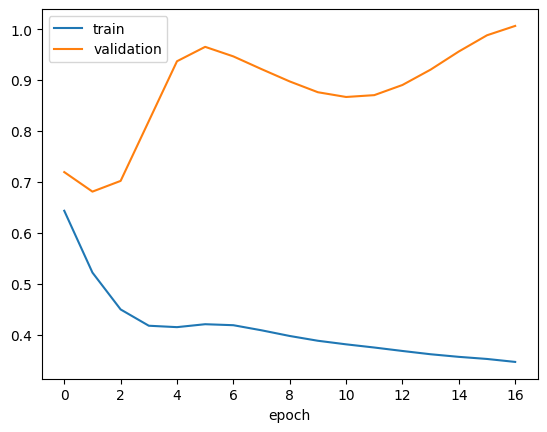

OK, it stopped early


In [8]:
Xt, Xv, yt, yv = train_test_split(Xtr, ytr, test_size=0.3, random_state=0, stratify=ytr)
net = build_big()
stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
h = net.fit(Xt, yt, validation_data=(Xv, yv), epochs=300, batch_size=16, callbacks=[stop], verbose=0)
print("stopped after", len(h.history["loss"]), "epochs; test accuracy:", round(net.evaluate(Xte, yte, verbose=0)[1], 3))
plt.plot(h.history["loss"], label="train"); plt.plot(h.history["val_loss"], label="validation"); plt.legend(); plt.xlabel("epoch"); plt.show()
assert len(h.history["loss"]) < 300; print("OK, it stopped early")

## Task 8: Softmax by hand
Scores `z = [2.0, 1.0, 0.1]`. Compute the three probabilities, check they add up to 1, and the loss if the true class is 0.

In [9]:
z = np.array([2.0, 1.0, 0.1])
e = np.exp(z)
p = e / e.sum()                # divide by the sum
loss0 = -np.log(p[0])        # true class is 0
print(p.round(3), round(p.sum(), 3), round(loss0, 3))
assert np.allclose(p, [0.659, 0.242, 0.099], atol=0.001) and abs(loss0 - 0.417) < 0.001; print("OK")

[0.659 0.242 0.099] 1.0 0.417
OK


## Task 9: Compare the fixes over several random starts
One run can mislead. Train each variant with 5 seeds and print the mean test accuracy. (This cell takes a minute or two.)

In [10]:
def test_acc(make, seeds=range(5)):
    accs = []
    for sd in seeds:
        m = make(sd); m.fit(Xtr, ytr, epochs=300, batch_size=16, verbose=0)
        accs.append(m.evaluate(Xte, yte, verbose=0)[1])
    return np.mean(accs)

results = {
    "big, no fix":  test_acc(lambda s: build_big(s)),
    "big + L2":     test_acc(lambda s: build_big(s, l2=0.01)),
    "big + dropout": test_acc(lambda s: build_big(s, dropout=0.5)),
}
for k, v in results.items(): print(f"{k:15s} {v:.3f}")
assert max(results["big + L2"], results["big + dropout"]) > results["big, no fix"]; print("OK, at least one fix beat doing nothing")

## Task 10: About your own project (answer in your own words)
1. Do you have a validation set separate from your test set? How big is each?
2. Draw (or describe) the training and validation loss curves you expect for your model. Is there a gap?
3. Which fix from today would you try first, and why?

Your answers: ______

## Bonus: tune lambda
Try `l2` = 0.001, 0.01 and 0.1 with one seed each and print the test accuracy. Which is best? What goes wrong when lambda is too big?

In [11]:
for lam in [0.001, 0.01, 0.1]:
    m = build_big(l2=lam); m.fit(Xtr, ytr, epochs=300, batch_size=16, verbose=0)
    print(lam, "train", round(m.evaluate(Xtr, ytr, verbose=0)[1], 3), "test", round(m.evaluate(Xte, yte, verbose=0)[1], 3))

0.001 train 0.933 test 0.823
0.01 train 0.85 test 0.859
0.1 train 0.75 test 0.831


## Wrap-up
- Overfitting = big gap between train and test. Judge models on unseen data and use several seeds.
- Fixes: more data, smaller model, L2, dropout, early stopping, augmentation (images).
- Softmax and sigmoid turn scores into probabilities; hidden layers use ReLU.
- Next: images and convolution (CNNs).